# Example of the `aitlas` toolbox in the context of multi class image classification

This notebook shows a sample implementation of a multi class image classification using the `aitlas` toolbox and the AID dataset.

In [ ]:
from aitlas.datasets import AIDDataset
from aitlas.models import ResNet50
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "/home/dragik/data/AID", 
    "csv_file": "/home/dragik/data/AID/aid_train.csv"
    }
dataset = AIDDataset(dataset_config)

## Show images from the dataset

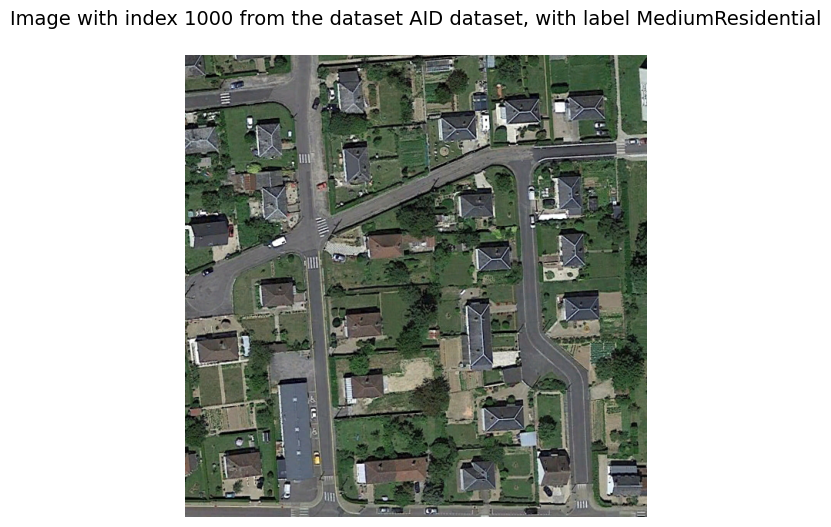

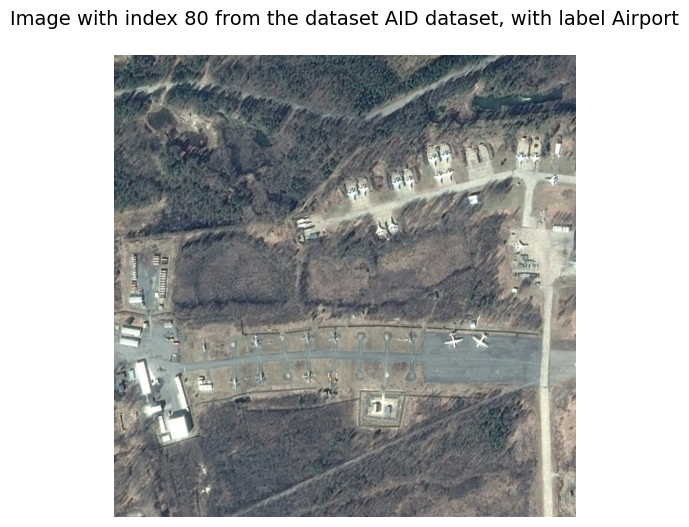

In [9]:
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(80)

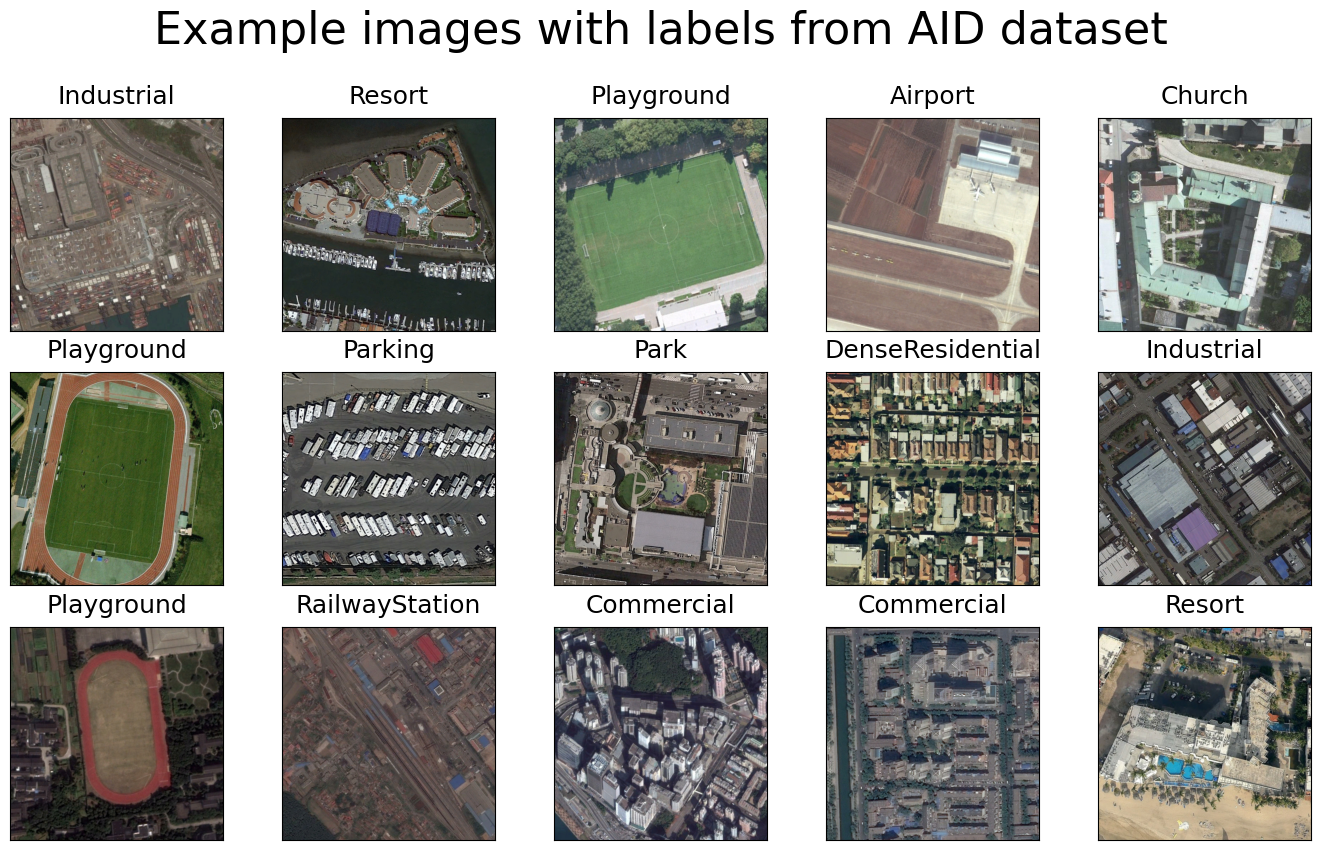

In [10]:
fig3 = dataset.show_batch(15)

## Inspect the data

In [11]:
dataset.show_samples()

,File name,Label
0,Bridge/bridge_53.jpg,Bridge
1,DenseResidential/denseresidential_360.jpg,DenseResidential
2,Industrial/industrial_61.jpg,Industrial
3,Meadow/meadow_99.jpg,Meadow
4,Church/church_156.jpg,Church
5,Commercial/commercial_9.jpg,Commercial
6,BareLand/bareland_211.jpg,BareLand
7,Farmland/farmland_324.jpg,Farmland
8,Beach/beach_163.jpg,Beach
9,DenseResidential/denseresidential_97.jpg,DenseResidential


In [12]:
dataset.data_distribution_table()

,Label,Count
0,Airport,216
1,BareLand,186
2,BaseballField,132
3,Beach,240
4,Bridge,216
5,Center,156
6,Church,144
7,Commercial,210
8,DenseResidential,246
9,Desert,180


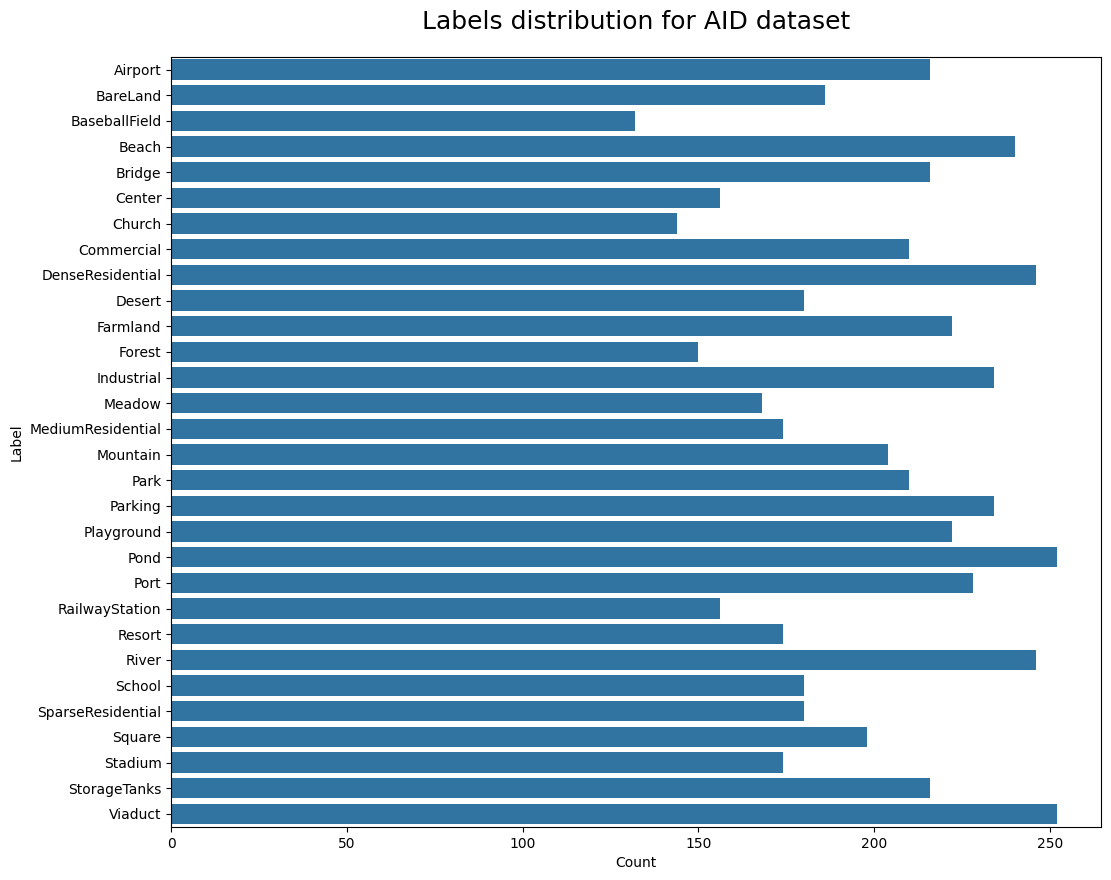

In [13]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

In [14]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/AID", 
    "csv_file": "/home/dragik/data/AID/aid_train.csv"
}

train_dataset = AIDDataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor()

test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/AID", 
    "csv_file": "/home/dragik/data/AID/aid_val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"],
}

test_dataset = AIDDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(6000, 2000)

## Setup and create the model for training

In [15]:
epochs = 10
model_directory = "/home/dragik/data/experiments/AID"
model_config = {
    "num_classes": 30,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"],
}
model = ResNet50(model_config)
model.prepare()

## Training and evaluation

In [16]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id="1",
)

2026-08-19 09:34:46,569 INFO Starting training.
training: 100%|██████████| 375/375 [00:12<00:00, 29.88it/s]
2026-08-19 09:34:59,175 INFO epoch: 1, time: 13, loss:  1.77634
testing on train set: 100%|██████████| 375/375 [00:12<00:00, 31.01it/s]
2026-08-19 09:35:11,938 INFO Accuracy:0.925, Precision Micro:0.925, Precision Macro:0.9255987411602077, Precision Weighted:0.9286518400665751, Precision per Class:[0.96153846 0.99350649 1.         0.98319328 1.         0.9140625
 0.79518072 0.75471698 0.91287879 0.8287037  0.969163   1.
 0.86610879 0.98224852 0.93103448 1.         0.87203791 0.99145299
 0.96938776 0.94230769 0.969163   0.91891892 0.75974026 0.99152542
 0.87068966 0.99431818 0.86764706 0.77130045 0.99530516 0.96183206], Recall Micro:0.925, Recall Macro:0.9203108158631835, Recall Weighted:0.925, Recall per Class:[0.92592593 0.82258065 0.97727273 0.975      0.97222222 0.75
 0.91666667 0.95238095 0.9796748  0.99444444 0.99099099 1.
 0.88461538 0.98809524 0.93103448 0.99509804 0.87619

0.1298937842709323

## Predictions

2026-08-19 11:02:53,095 INFO Loading checkpoint /home/dragik/data/experiments/AID/checkpoint.pth.tar
2026-08-19 11:02:53,279 INFO Loaded checkpoint /home/dragik/data/experiments/AID/checkpoint.pth.tar at epoch 11


2000


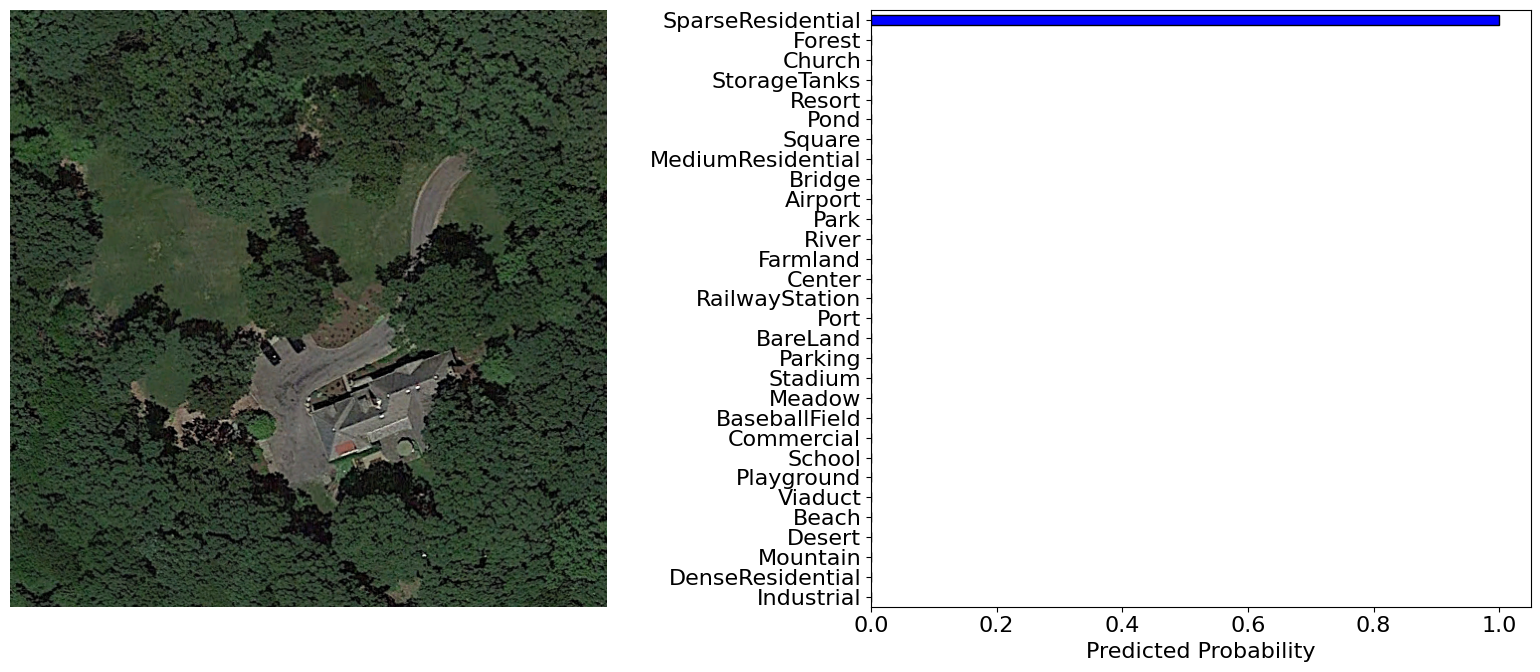

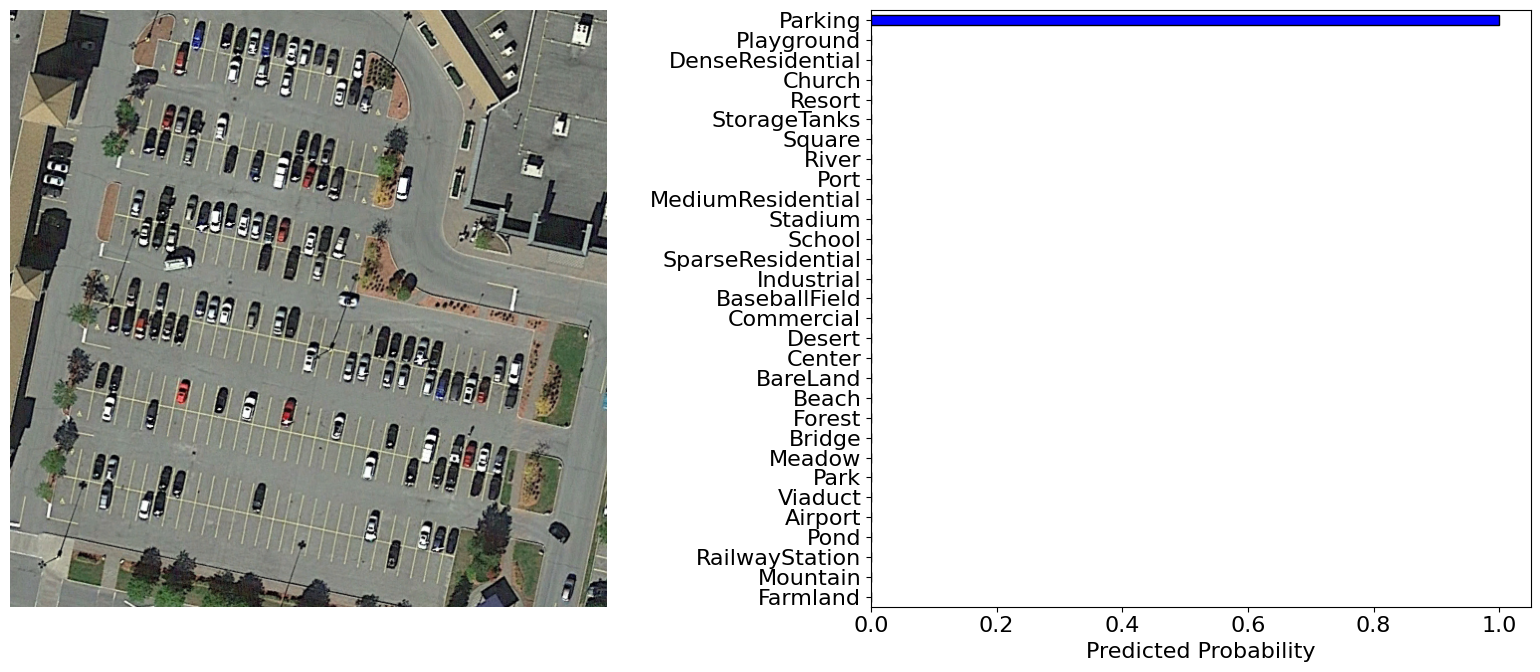

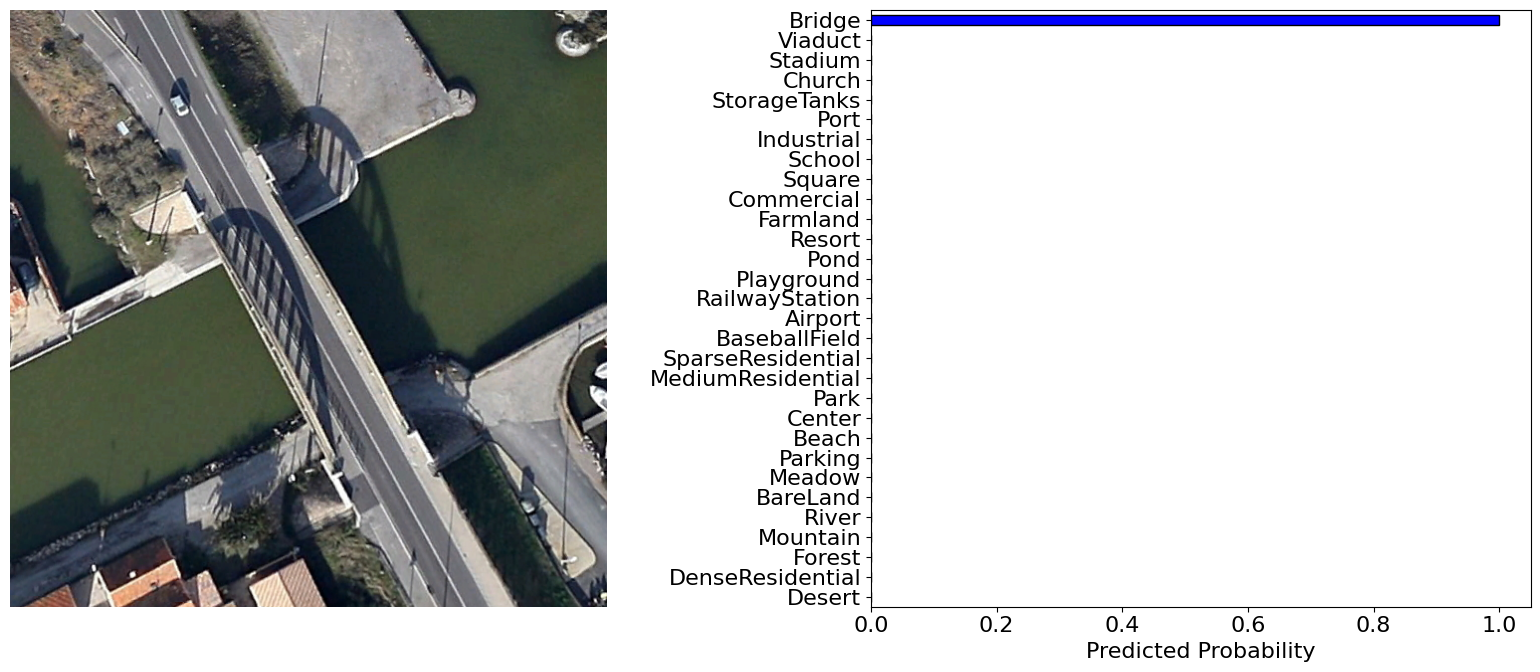

In [18]:
model_path = "/home/dragik/data/experiments/AID/checkpoint.pth.tar"
labels = [
    "Airport",
    "BareLand",
    "BaseballField",
    "Beach",
    "Bridge",
    "Center",
    "Church",
    "Commercial",
    "DenseResidential",
    "Desert",
    "Farmland",
    "Forest",
    "Industrial",
    "Meadow",
    "MediumResidential",
    "Mountain",
    "Park",
    "Parking",
    "Playground",
    "Pond",
    "Port",
    "RailwayStation",
    "Resort",
    "River",
    "School",
    "SparseResidential",
    "Square",
    "Stadium",
    "StorageTanks",
    "Viaduct",
]
transform = ResizeCenterCropToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir": "/home/dragik/data/AID", 
    "csv_file": "/home/dragik/data/AID/aid_test.csv"
}

test_dataset = AIDDataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_image(image, labels, transform)